# 05 Ranges for the planner, and the forecast from the newest data

**Purpose:** A planner of federal reception places needs a range, and above all an upper bound, not only one number. We add simple 80% and 90% ranges to the forecasts of our chosen model, check how often the actual number falls inside them, and give the forecast from the newest data (origin September 2026).
**Input:** `../data/processed/asylum_clean.csv`, `../data/processed/backtest_forecasts_regression.csv` (from `02b`) and `../data/processed/test_forecasts.csv` (from `04`).
**Output:** `../output/tables/05_range_coverage.csv`, `../output/tables/05_forecast_from_2026_09.csv` and one figure in `../output/figures/`.

Our plan first had quantile forecasts with pinball loss; we removed them because they go beyond the course (Johannes' feedback, point 2). The ranges here are simpler: they only use the **past forecast errors** of the model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. How the ranges are built

At an origin $t$ and horizon $h$, take the errors in logs, $\log y - \log \hat y$, of all **earlier** forecasts of the same horizon whose month is already known at $t$. The 80% range goes from the forecast times $e^{q_{10}}$ to the forecast times $e^{q_{90}}$, where $q_{10}$ and $q_{90}$ are the 10th and 90th percentiles of these errors (for the 90% range: $q_5$ and $q_{95}$). So if the model was 20% too low in the worst tenth of past months, the upper bound is 20% above the forecast. We need at least 24 past errors, so the first ranges are for 2015.

The range uses only information known at each origin, so checking how often the actual number falls inside is an honest check, like the backtest itself.

*Not seen in class:* `Series.quantile(0.1)` gives the 10th percentile.

In [2]:
MIN_PAST = 24
LEVELS = {"80%": (0.10, 0.90), "90%": (0.05, 0.95)}
TEST_START = pd.Timestamp("2024-10-01")

def read(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    data["origin"] = pd.to_datetime(data["origin"])
    return data

backtest = read("../data/processed/backtest_forecasts_regression.csv")
test = read("../data/processed/test_forecasts.csv")
fc = pd.concat([backtest[backtest["model"] == "Linear regression"], test[test["model"] == "Linear regression"]], ignore_index=True)
fc = fc[["origin", "month", "h", "forecast_log", "actual_log", "forecast", "actual"]].sort_values(["h", "origin"]).reset_index(drop=True)
fc["log_error"] = fc["actual_log"] - fc["forecast_log"]

rows = []
for h, g in fc.groupby("h"):
    for _, r in g.iterrows():
        past = g.loc[g["month"] <= r["origin"], "log_error"]        # errors already known at the origin
        if len(past) < MIN_PAST:
            continue
        out = {"h": h, "origin": r["origin"], "month": r["month"], "forecast": r["forecast"], "actual": r["actual"]}
        for level, (lo, hi) in LEVELS.items():
            out[f"low {level}"] = r["forecast"] * np.exp(past.quantile(lo))
            out[f"high {level}"] = r["forecast"] * np.exp(past.quantile(hi))
        rows.append(out)
ranges = pd.DataFrame(rows)
ranges["period"] = np.where(ranges["month"] >= TEST_START, "test", "backtest")
for level in LEVELS:
    ranges[f"inside {level}"] = (ranges["actual"] >= ranges[f"low {level}"]) & (ranges["actual"] <= ranges[f"high {level}"])
    ranges[f"above {level}"] = ranges["actual"] > ranges[f"high {level}"]
    ranges[f"width {level}"] = ranges[f"high {level}"] - ranges[f"low {level}"]
print("First month with a range:", ranges["month"].min().strftime("%Y-%m"), "| ranges:", len(ranges))

First month with a range: 2015-01 | ranges: 414


## 2. How often is the actual number inside the range?

An 80% range should contain about 80% of the actual numbers, and the actual number should be above the upper bound of the 90% range in about 5% of the months.

In [3]:
coverage = ranges.groupby(["h", "period"]).agg(
    months=("actual", "size"),
    inside_80=("inside 80%", "mean"), inside_90=("inside 90%", "mean"),
    above_upper_90=("above 90%", "mean"),
    width_80=("width 80%", "mean"), forecast=("forecast", "mean"))
coverage["width_80_in_%_of_forecast"] = 100 * coverage["width_80"] / coverage["forecast"]
coverage = coverage.round({"inside_80": 2, "inside_90": 2, "above_upper_90": 2, "width_80": 0, "forecast": 0,
                           "width_80_in_%_of_forecast": 0})
coverage.to_csv("../output/tables/05_range_coverage.csv")
coverage

months  inside_80  inside_90  above_upper_90  width_80  forecast  \
h period                                                                       
1 backtest     117       0.81       0.90            0.04     781.0    1841.0   
  test          24       0.96       0.96            0.00     740.0    2027.0   
2 backtest     115       0.80       0.89            0.07    1172.0    1826.0   
  test          23       1.00       1.00            0.00    1139.0    2026.0   
3 backtest     113       0.80       0.88            0.06    1507.0    1825.0   
  test          22       1.00       1.00            0.00    1481.0    2034.0   

            width_80_in_%_of_forecast  
h period                               
1 backtest                       42.0  
  test                           37.0  
2 backtest                       64.0  
  test                           56.0  
3 backtest                       83.0  
  test                           73.0

The same check by period at $h = 2$, with the crisis periods of `03` shown apart.

In [4]:
h2 = ranges[ranges["h"] == 2].copy()
h2["part"] = np.where(h2["month"] < pd.Timestamp("2015-07-01"), "2015-01 to 2015-06",
             np.where(h2["month"] < pd.Timestamp("2017-01-01"), "2015-07 to 2016-12 (crisis)",
             np.where(h2["month"] < pd.Timestamp("2020-01-01"), "2017 to 2019",
             np.where(h2["month"] < TEST_START, "2020-01 to 2024-09", "test 2024-10 to 2026-09"))))
h2.groupby("part").agg(months=("actual", "size"), inside_80=("inside 80%", "mean"),
                       above_upper_80=("above 80%", "mean"), width_80=("width 80%", "mean")).round(2)

,months,inside_80,above_upper_80,width_80
part,,,,
2015-01 to 2015-06,4,0.50,0.50,662.59
2015-07 to 2016-12 (crisis),18,0.72,0.06,2463.43
2017 to 2019,36,0.89,0.11,801.16
2020-01 to 2024-09,57,0.79,0.12,1034.12
test 2024-10 to 2026-09,23,1.00,0.00,1138.73


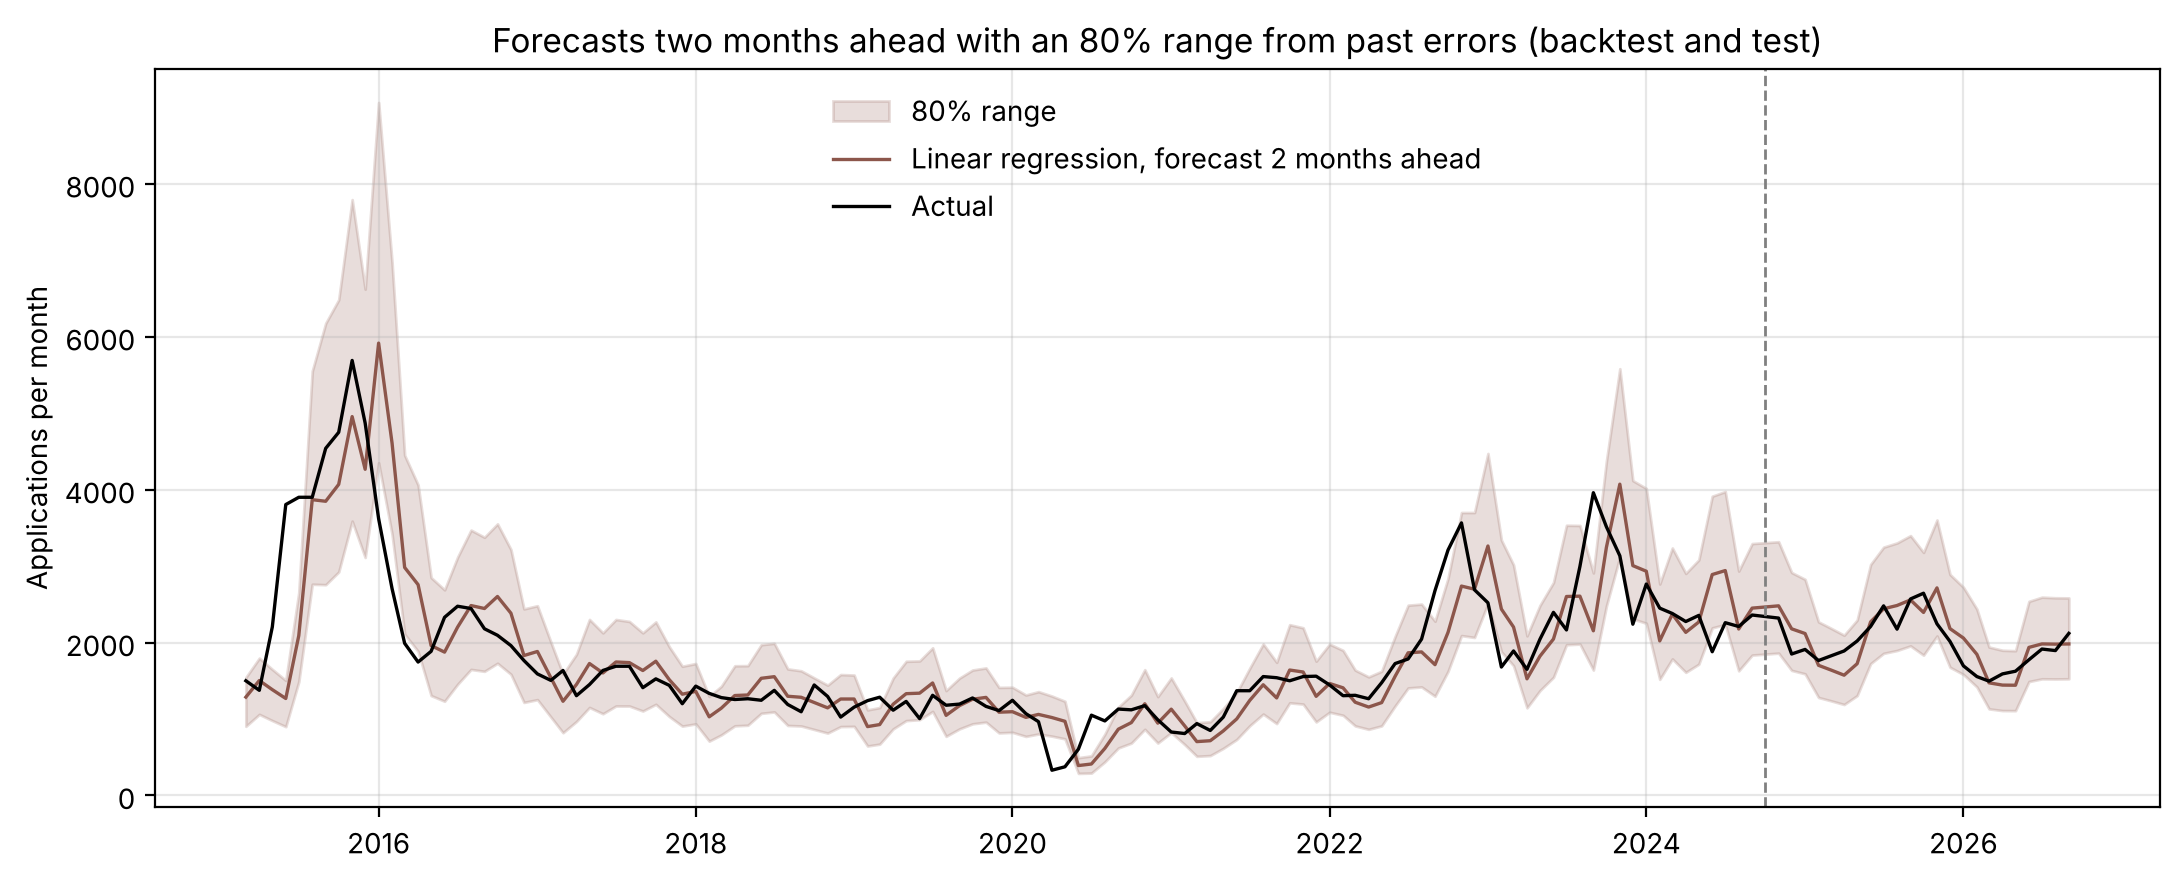

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(h2["month"], h2["low 80%"], h2["high 80%"], color=plt.cm.tab10(5), alpha=0.2, label="80% range")
ax.plot(h2["month"], h2["forecast"], color=plt.cm.tab10(5), linewidth=1.2, label="Linear regression, forecast 2 months ahead")
ax.plot(h2["month"], h2["actual"], color="black", linewidth=1.2, label="Actual")
ax.axvline(TEST_START, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Applications per month")
ax.set_title("Forecasts two months ahead with an 80% range from past errors (backtest and test)")
ax.legend(loc="upper center", frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/05_ranges_h2.png")
plt.show()

**What we see.**
- **In the backtest, the ranges do what they promise:** the 80% range contains 80% to 81% of the actual numbers at every horizon, the 90% range 88% to 90%. The actual number is above the upper bound of the 90% range in 4% to 7% of the months (5% expected).
- The ranges are wide: at $h = 2$, the 80% range is on average 1,172 applications wide, 64% of the forecast (roughly ±30%); 42% at $h = 1$ and 83% at $h = 3$.
- **In the test period they are too wide:** they contain every actual number at $h = 2$ and $h = 3$. The test period was calm (`04_test`), while the past errors still include the 2015-16 crisis.
- **In a crisis they are too narrow:** in the first half of 2015 only 2 of 4 months are inside (the past errors came from calm years), and in July 2015 to 2016 72%. In the figure, the band widens only after the big misses.

**What this means for us.** The ranges are honest on average over the backtest and easy to explain, but they react late: right after a calm period they are too narrow, after a crisis too wide. For a planner, the upper bound of the 90% range is a reasonable number to prepare for in normal times, not in a new crisis.

## 3. The forecast from the newest data

What a planner would get from our model with the data up to September 2026: the linear regression of `02b`, fitted on all months known at that origin (the function `make_table` is copied from `04_test.ipynb`), with the ranges from all past errors.

These forecasts were made on 20 November 2026, after SEM had published October (mid-November). So **October is not a live test**, even though the model did not use it. Our plan had foreseen a live test locked before SEM's release; we did not lock one in time.

In [6]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")
y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index
last = len(months) - 1

def make_table(h):
    # Copied from 04_test (rows up to the last month; the newest rows have no target yet)
    rows = []
    for t in range(12, len(log_y)):
        forecast_month = months[t] + pd.DateOffset(months=h)
        rows.append({
            "t": t,
            "change_last_month": log_y[t] - log_y[t - 1],
            "change_month_before": log_y[t - 1] - log_y[t - 2],
            "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
            "calendar_month": forecast_month.month,
            "target": log_y[t + h] - log_y[t] if t + h <= last else np.nan,
        })
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month").astype(float).drop(columns="month_1")
    X = pd.concat([table[["change_last_month", "change_month_before", "same_change_last_year"]], dummies], axis=1)
    return X, table["target"]

rows = []
for h in [1, 2, 3]:
    X, target = make_table(h)
    train_rows = [t for t in X.index if t + h <= last]
    model = make_pipeline(StandardScaler(), LinearRegression()).fit(X.loc[train_rows], target.loc[train_rows])
    forecast = np.exp(log_y[last] + model.predict(X.loc[[last]])[0])
    past = fc.loc[(fc["h"] == h) & (fc["month"] <= months[last]), "log_error"]
    rows.append({"month": (months[last] + pd.DateOffset(months=h)).strftime("%Y-%m"), "h": h, "forecast": round(forecast),
                 "low 80%": round(forecast * np.exp(past.quantile(0.10))), "high 80%": round(forecast * np.exp(past.quantile(0.90))),
                 "high 90% (plan for)": round(forecast * np.exp(past.quantile(0.95)))})
newest = pd.DataFrame(rows).set_index("month")
newest.to_csv("../output/tables/05_forecast_from_2026_09.csv")
print("Origin:", months[last].strftime("%Y-%m"), "(last known month)")
newest

Origin: 2026-09 (last known month)


,h,forecast,low 80%,high 80%,high 90% (plan for)
month,,,,,
2026-10,1,2226,1873,2669,3061
2026-11,2,2178,1678,2839,3361
2026-12,3,1854,1350,2599,3146


**What we see.** From the data up to September 2026, the model expects 2,226 applications in October 2026 (80% range 1,873 to 2,669), 2,178 in November (1,678 to 2,839) and 1,854 in December (1,350 to 2,599), the usual fall at the end of the year. A planner who wants to be covered in 95% of months would prepare for about 3,061, 3,361 and 3,146.

## Summary

- **Ranges from past errors:** 10th to 90th percentile (80%) and 5th to 95th percentile (90%) of the earlier forecast errors in logs, using only errors known at each origin.
- **Check:** in the backtest the 80% range contains 80% to 81% of the actual numbers and the 90% range 88% to 90%; in the calm test period they are too wide (96% to 100%), in the 2015-16 crisis too narrow (72%). At $h = 2$ the 80% range is about ±30% of the forecast.
- **Forecast from September 2026:** October 2,226 (80%: 1,873 to 2,669), November 2,178, December 1,854. Not a live test: SEM published October before these forecasts were made.
- **Not seen in class (marked above):** `Series.quantile`.